In [18]:
import os, time, random
import pandas as pd
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm
from google import genai
from dotenv import load_dotenv

load_dotenv()
os.makedirs("results", exist_ok=True)

client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
MODEL = "gemini-3.1-flash-lite"
print("Gemini client ready:", MODEL)

Gemini client ready: gemini-3.1-flash-lite


In [19]:
dataset = load_dataset("nyu-mll/glue", "sst2")
LABEL_TO_TEXT = {0: "negative", 1: "positive"}

train_sentences = dataset["train"]["sentence"]
train_labels    = dataset["train"]["label"]
val_sentences   = dataset["validation"]["sentence"]
val_labels      = dataset["validation"]["label"]

print(f"Train: {len(train_sentences)} | Val: {len(val_sentences)} | Test: {len(dataset['test'])}")

Train: 67349 | Val: 872 | Test: 1821


In [20]:
def sample_shots(k, seed=42):
    """Draw k balanced examples from the TRAIN split. k=0 returns []."""
    if k == 0:
        return []
    rng = random.Random(seed)
    pos_idx = [i for i, y in enumerate(train_labels) if y == 1]
    neg_idx = [i for i, y in enumerate(train_labels) if y == 0]
    n_pos = k // 2
    n_neg = k - n_pos
    chosen = rng.sample(pos_idx, n_pos) + rng.sample(neg_idx, n_neg)
    rng.shuffle(chosen)
    return [{"sentence": train_sentences[i], "label": train_labels[i]} for i in chosen]

In [21]:
INSTRUCTION = "Classify the sentiment of the movie review as either positive or negative."

def build_prompt(test_sentence, shots):
    parts = [INSTRUCTION, ""]
    for ex in shots:
        parts.append(f'Review: "{ex["sentence"]}"')
        parts.append(f"Sentiment: {LABEL_TO_TEXT[ex['label']]}")
        parts.append("")
    parts.append(f'Review: "{test_sentence}"')
    parts.append("Sentiment:")
    return "\n".join(parts)

In [22]:
VALID = {"positive": 1, "negative": 0}

def parse_response(text):
    if not text:
        return None, "parse_failure"
    cleaned = text.strip().lower().rstrip(".").strip('"').strip()
    # Strip a leading "sentiment:" prefix the model sometimes copies
    if cleaned.startswith("sentiment:"):
        cleaned = cleaned[len("sentiment:"):].strip()
    first_word = cleaned.split()[0] if cleaned.split() else ""
    if first_word in VALID:
        return int(VALID[first_word]), "ok"
    return None, "parse_failure"

In [29]:
def classify_with_retry(prompt, max_attempts=6):
    for attempt in range(max_attempts):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config={"temperature": 0.0, "max_output_tokens": 10},
            )
            return response.text
        except Exception as e:
            msg = str(e).lower()
            is_retryable = (
                "429" in msg or "rate" in msg or "quota" in msg
                or "503" in msg or "unavailable" in msg or "overloaded" in msg
                or "500" in msg or "502" in msg or "504" in msg
                or "remote" in msg or "disconnected" in msg
                or "connection" in msg or "timeout" in msg
                or "read" in msg and "error" in msg
            )
            if is_retryable:
                wait = min(2 ** attempt + random.random(), 45)
                print(f"  Transient ({type(e).__name__}), waiting {wait:.1f}s "
                      f"(attempt {attempt+1}/{max_attempts})")
                time.sleep(wait)
            else:
                print(f"  {type(e).__name__}: {str(e)[:200]}")
                raise
    raise RuntimeError(f"Max retries exceeded after {max_attempts} attempts")

In [24]:
def evaluate_k(k, seed=42, max_examples=None, sleep=4.0):
    shots = sample_shots(k, seed=seed)
    n = len(val_sentences) if max_examples is None else min(max_examples, len(val_sentences))
    partial_path = f"results/partial_k{k}_seed{seed}.csv"

    if os.path.exists(partial_path):
        existing = pd.read_csv(partial_path)
        results = existing.to_dict("records")
        start = len(results)
        print(f"  Resuming k={k} from index {start}")
    else:
        results = []
        start = 0

    for i in tqdm(range(start, n), desc=f"k={k}"):
        sentence = val_sentences[i]
        true_label = val_labels[i]
        prompt = build_prompt(sentence, shots)
        raw = classify_with_retry(prompt)
        pred, status = parse_response(raw)
        results.append({
            "k": k, "seed": seed, "index": i,
            "sentence": sentence, "true_label": true_label,
            "raw_response": raw, "predicted_label": pred, "status": status,
        })
        if (i + 1) % 25 == 0:
            pd.DataFrame(results).to_csv(partial_path, index=False)
        time.sleep(sleep)

    df = pd.DataFrame(results)
    df.to_csv(f"results/predictions_k{k}_seed{seed}.csv", index=False)
    df.to_csv(partial_path, index=False)
    return df

In [25]:
print("=== SMOKE TEST: 5 examples per k ===")
for k in [0, 3, 10]:
    df_test = evaluate_k(k=k, seed=42, max_examples=5, sleep=1.0)
    print(f"\nk={k}:")
    print(df_test[["raw_response", "predicted_label", "status"]].to_string())
    print(f"ok: {(df_test['status']=='ok').sum()}/5")

=== SMOKE TEST: 5 examples per k ===


k=0:   0%|          | 0/5 [00:00<?, ?it/s]

  Transient error (ServerError), waiting 1.2s (attempt 1/6)
  Transient error (ServerError), waiting 2.2s (attempt 2/6)

k=0:
          raw_response  predicted_label status
0  Sentiment: Positive                1     ok
1  Sentiment: Negative                0     ok
2  Sentiment: Positive                1     ok
3  Sentiment: Positive                1     ok
4  Sentiment: Negative                0     ok
ok: 5/5


k=3:   0%|          | 0/5 [00:00<?, ?it/s]


k=3:
          raw_response  predicted_label status
0             positive                1     ok
1  Sentiment: negative                0     ok
2             positive                1     ok
3             positive                1     ok
4             negative                0     ok
ok: 5/5


k=10:   0%|          | 0/5 [00:00<?, ?it/s]


k=10:
          raw_response  predicted_label status
0             positive                1     ok
1  Sentiment: negative                0     ok
2  Sentiment: positive                1     ok
3  Sentiment: positive                1     ok
4             negative                0     ok
ok: 5/5


In [32]:
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(df):
    valid = df[df["status"] == "ok"]
    if len(valid) == 0:
        return {"n": 0, "accuracy": None, "macro_f1": None, "parse_failures": len(df)}
    return {
        "n": len(valid),
        "accuracy": accuracy_score(valid["true_label"], valid["predicted_label"]),
        "macro_f1": f1_score(valid["true_label"], valid["predicted_label"], average="macro"),
        "parse_failures": len(df) - len(valid),
    }

In [33]:
SUBSET_SIZE = 150
all_results = []
for k in [0, 3, 10]:
    print(f"\n=== k={k} on {SUBSET_SIZE} examples ===")
    df_k = evaluate_k(k=k, seed=42, max_examples=SUBSET_SIZE, sleep=4.0)
    all_results.append(df_k)
    print(compute_metrics(df_k))

results_df = pd.concat(all_results, ignore_index=True)
results_df.to_csv("results/predictions_val_subset.csv", index=False)


=== k=0 on 150 examples ===
  Resuming k=0 from index 150


k=0: 0it [00:00, ?it/s]

{'n': 150, 'accuracy': 0.96, 'macro_f1': 0.9599928876244666, 'parse_failures': 0}

=== k=3 on 150 examples ===
  Resuming k=3 from index 5


k=3:   0%|          | 0/145 [00:00<?, ?it/s]

  Transient (RemoteProtocolError), waiting 1.8s (attempt 1/6)
  Transient (ServerError), waiting 1.6s (attempt 1/6)
  Transient (ServerError), waiting 1.3s (attempt 1/6)
  Transient (ServerError), waiting 2.7s (attempt 2/6)
  Transient (ServerError), waiting 1.4s (attempt 1/6)
  Transient (ServerError), waiting 1.4s (attempt 1/6)
  Transient (ServerError), waiting 1.3s (attempt 1/6)
  Transient (ServerError), waiting 3.0s (attempt 2/6)
{'n': 150, 'accuracy': 0.9733333333333334, 'macro_f1': 0.9733285917496444, 'parse_failures': 0}

=== k=10 on 150 examples ===
  Resuming k=10 from index 5


k=10:   0%|          | 0/145 [00:00<?, ?it/s]

  Transient (ServerError), waiting 1.6s (attempt 1/6)
  Transient (ServerError), waiting 1.1s (attempt 1/6)
  Transient (ServerError), waiting 1.4s (attempt 1/6)
  Transient (ClientError), waiting 1.6s (attempt 1/6)
  Transient (ClientError), waiting 1.1s (attempt 1/6)
  Transient (ClientError), waiting 2.6s (attempt 2/6)
  Transient (ClientError), waiting 1.7s (attempt 1/6)
  Transient (ClientError), waiting 1.9s (attempt 1/6)
  Transient (ClientError), waiting 1.7s (attempt 1/6)
  Transient (ClientError), waiting 2.8s (attempt 2/6)
  Transient (ClientError), waiting 4.7s (attempt 3/6)
  Transient (ClientError), waiting 8.2s (attempt 4/6)
  Transient (ClientError), waiting 16.0s (attempt 5/6)
  Transient (ClientError), waiting 32.5s (attempt 6/6)


RuntimeError: Max retries exceeded after 6 attempts

In [38]:
def compute_metrics(df):
    valid = df[df["status"] == "ok"]
    if len(valid) == 0:
        return {"n": 0, "accuracy": None, "macro_f1": None, "parse_failures": len(df)}
    return {
        "n": len(valid),
        "accuracy": accuracy_score(valid["true_label"], valid["predicted_label"]),
        "macro_f1": f1_score(valid["true_label"], valid["predicted_label"], average="macro"),
        "parse_failures": len(df) - len(valid),
    }

BASELINE_ACC = 0.8188 
BASELINE_F1  = 0.82   

rows = [{"condition": "TF-IDF + LR baseline", "n": 872,
         "accuracy": BASELINE_ACC, "macro_f1": BASELINE_F1, "parse_failures": 0}]
for k in [0, 3, 10]:
    rows.append({"condition": f"{k}-shot", **compute_metrics(results_df[results_df["k"] == k])})

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))
comparison.to_csv("results/comparison_val.csv", index=False)

           condition   n  accuracy  macro_f1  parse_failures
TF-IDF + LR baseline 872  0.818800  0.820000               0
              0-shot 150  0.960000  0.959993               0
              3-shot 150  0.973333  0.973329               0
             10-shot 125  0.952000  0.951923               0


In [39]:
import pandas as pd

results_df = pd.read_csv("results/predictions_val_subset.csv")
valid = results_df[results_df["status"] == "ok"]
wrong = valid[valid["predicted_label"] != valid["true_label"]]

print(f"Total valid: {len(valid)} | Wrong: {len(wrong)} ({len(wrong)/len(valid)*100:.1f}%)")
print(f"\nErrors per k:\n{wrong.groupby('k').size()}\n")
wrong.to_csv("results/wrong_predictions.csv", index=False)

# Print all wrong predictions with readable labels
for _, r in wrong.iterrows():
    true_txt = "positive" if r["true_label"] == 1 else "negative"
    pred_txt = "positive" if r["predicted_label"] == 1 else "negative"
    print(f"[k={int(r['k'])}] TRUE={true_txt:8s} PRED={pred_txt:8s} | {r['sentence']}")

Total valid: 425 | Wrong: 16 (3.8%)

Errors per k:
k
0     6
3     4
10    6
dtype: int64

[k=0] TRUE=positive PRED=negative | we root for ( clara and paul ) , even like them , though perhaps it 's an emotion closer to pity . 
[k=0] TRUE=positive PRED=negative | if you 're hard up for raunchy college humor , this is your ticket right here . 
[k=0] TRUE=negative PRED=positive | you wo n't like roger , but you will quickly recognize him . 
[k=0] TRUE=negative PRED=positive | this riveting world war ii moral suspense story deals with the shadow side of american culture : racial prejudice in its ugly and diverse forms . 
[k=0] TRUE=positive PRED=negative | does paint some memorable images ... , but makhmalbaf keeps her distance from the characters 
[k=0] TRUE=positive PRED=negative | hilariously inept and ridiculous . 
[k=3] TRUE=positive PRED=negative | we root for ( clara and paul ) , even like them , though perhaps it 's an emotion closer to pity . 
[k=3] TRUE=negative PRED=positive | t

In [42]:
import pandas as pd

categories = pd.DataFrame([
    # ----- k=0 -----
    {"k": 0, "sentence": "we root for ( clara and paul ) , even like them , though perhaps it 's an emotion closer to pity .",
     "true_label": 1, "predicted_label": 0, "category": "mixed_sentiment",
     "note": "positive framing ('root for', 'like') undercut by 'pity'"},
    {"k": 0, "sentence": "if you 're hard up for raunchy college humor , this is your ticket right here .",
     "true_label": 1, "predicted_label": 0, "category": "subtle_intensity",
     "note": "'raunchy'/'hard up' read as negative; sentence is a positive recommendation"},
    {"k": 0, "sentence": "you wo n't like roger , but you will quickly recognize him .",
     "true_label": 0, "predicted_label": 1, "category": "negation",
     "note": "negated preference 'won't like' overlooked; positive clause dominated"},
    {"k": 0, "sentence": "this riveting world war ii moral suspense story deals with the shadow side of american culture : racial prejudice in its ugly and diverse forms .",
     "true_label": 0, "predicted_label": 1, "category": "mixed_sentiment",
     "note": "'riveting' primes positive; negative subject matter is the true label driver"},
    {"k": 0, "sentence": "does paint some memorable images ... , but makhmalbaf keeps her distance from the characters",
     "true_label": 1, "predicted_label": 0, "category": "mixed_sentiment",
     "note": "contrast with 'but'; negative clause dominated despite positive gold label"},
    {"k": 0, "sentence": "hilariously inept and ridiculous .",
     "true_label": 1, "predicted_label": 0, "category": "sarcasm",
     "note": "surface-negative words ('inept', 'ridiculous') framed positively by 'hilariously'"},

    # ----- k=3 -----
    {"k": 3, "sentence": "we root for ( clara and paul ) , even like them , though perhaps it 's an emotion closer to pity .",
     "true_label": 1, "predicted_label": 0, "category": "mixed_sentiment",
     "note": "same failure as k=0; shots did not correct it"},
    {"k": 3, "sentence": "this riveting world war ii moral suspense story deals with the shadow side of american culture : racial prejudice in its ugly and diverse forms .",
     "true_label": 0, "predicted_label": 1, "category": "mixed_sentiment",
     "note": "same failure as k=0"},
    {"k": 3, "sentence": "does paint some memorable images ... , but makhmalbaf keeps her distance from the characters",
     "true_label": 1, "predicted_label": 0, "category": "mixed_sentiment",
     "note": "same failure as k=0"},
    {"k": 3, "sentence": "hilariously inept and ridiculous .",
     "true_label": 1, "predicted_label": 0, "category": "sarcasm",
     "note": "same failure as k=0"},

    # ----- k=10 -----
    {"k": 10, "sentence": "we root for ( clara and paul ) , even like them , though perhaps it 's an emotion closer to pity .",
     "true_label": 1, "predicted_label": 0, "category": "mixed_sentiment",
     "note": "same failure across all k"},
    {"k": 10, "sentence": "fresnadillo 's dark and jolting images have a way of plying into your subconscious like the nightmare you had a week ago that wo n't go away .",
     "true_label": 1, "predicted_label": 0, "category": "subtle_intensity",
     "note": "positive review of a horror film; surface words ('dark','nightmare') are praise for effectiveness"},
    {"k": 10, "sentence": "you wo n't like roger , but you will quickly recognize him .",
     "true_label": 0, "predicted_label": 1, "category": "negation",
     "note": "same failure as k=0"},
    {"k": 10, "sentence": "this riveting world war ii moral suspense story deals with the shadow side of american culture : racial prejudice in its ugly and diverse forms .",
     "true_label": 0, "predicted_label": 1, "category": "mixed_sentiment",
     "note": "same failure across all k"},
    {"k": 10, "sentence": "does paint some memorable images ... , but makhmalbaf keeps her distance from the characters",
     "true_label": 1, "predicted_label": 0, "category": "mixed_sentiment",
     "note": "same failure across all k"},
    {"k": 10, "sentence": "hilariously inept and ridiculous .",
     "true_label": 1, "predicted_label": 0, "category": "sarcasm",
     "note": "same failure across all k"},
])

categories.to_csv("results/error_categories.csv", index=False)

print("By category:")
print(categories.groupby("category").size().sort_values(ascending=False))
print("\nBy k and category:")
print(categories.groupby(["k", "category"]).size())

By category:
category
mixed_sentiment     9
sarcasm             3
negation            2
subtle_intensity    2
dtype: int64

By k and category:
k   category        
0   mixed_sentiment     3
    negation            1
    sarcasm             1
    subtle_intensity    1
3   mixed_sentiment     3
    sarcasm             1
10  mixed_sentiment     3
    negation            1
    sarcasm             1
    subtle_intensity    1
dtype: int64


Matplotlib is building the font cache; this may take a moment.


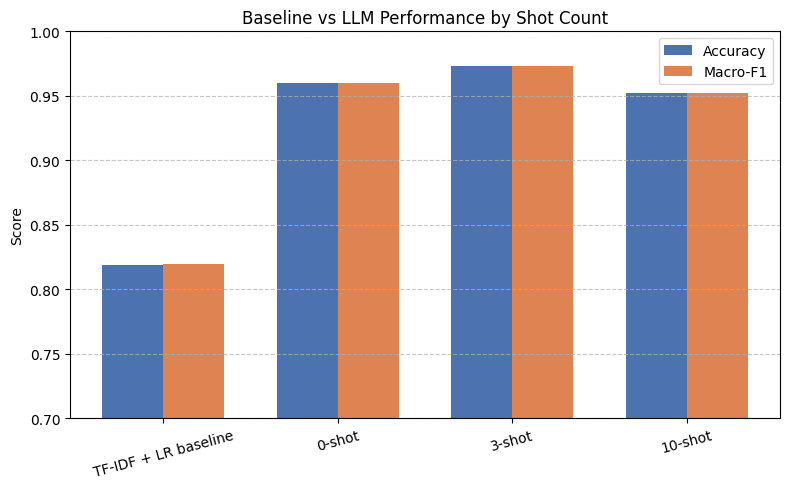

In [45]:
import matplotlib.pyplot as plt
import pandas as pd

# Load your final comparison table
df = pd.read_csv("results/comparison_val.csv")

# Set up the plot
fig, ax = plt.subplots(figsize=(8, 5))

# Create grouped bar chart
x = range(len(df))
width = 0.35

ax.bar([i - width/2 for i in x], df["accuracy"], width, label="Accuracy", color="#4C72B0")
ax.bar([i + width/2 for i in x], df["macro_f1"], width, label="Macro-F1", color="#DD8452")

# Labels and formatting
ax.set_ylabel("Score")
ax.set_title("Baseline vs LLM Performance by Shot Count")
ax.set_xticks(x)
ax.set_xticklabels(df["condition"], rotation=15)
ax.set_ylim(0.70, 1.00) 
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig("results/performance_plot.png", dpi=300) 
plt.show()

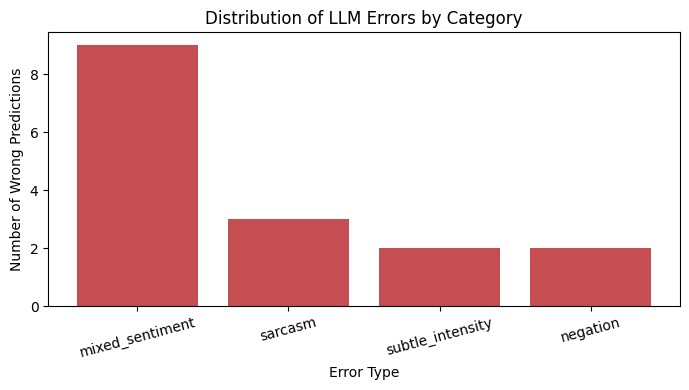

In [46]:
# Load your error categories
errors = pd.read_csv("results/error_categories.csv")

# Count the errors by category
error_counts = errors["category"].value_counts()

# Plot
plt.figure(figsize=(7, 4))
plt.bar(error_counts.index, error_counts.values, color="#C44E52")

plt.title("Distribution of LLM Errors by Category")
plt.ylabel("Number of Wrong Predictions")
plt.xlabel("Error Type")
plt.xticks(rotation=15)

plt.tight_layout()
plt.savefig("results/error_distribution.png", dpi=300)
plt.show()